# Лекція 4. Трансформери та мовні моделі.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [1]:
import sys
import os
import math
import time
import random

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

### 0.1. Перевіряємо чи ми точно в Colab

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має виконуватися в Google Colab (https://colab.research.google.com/)"


Running in Colab: True


### 0.2. Використовуємо графічний прискорювач, якщо доступний.
На Colab зазвичай є безкоштовний GPU (T4).
Використовуємо його, якщо він доступний.
Якщо ні, залишаємося на CPU.

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Використовуємо: cuda
GPU: Tesla T4


### 0.3. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінти mini-GPT й логи TensorBoard пережили
перезапуск.

In [4]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lecture4"

os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lecture4


---
## 1. Корпус: українська поезія

Для mini-GPT з нуля потрібен текстовий корпус однією мовою, достатньо
великий, щоб модель могла вивчити бодай прості закономірності.

Використовуємо датасет [`RudyiVT/ukrainian-poems`](https://huggingface.co/datasets/RudyiVT/ukrainian-poems)
(17 918 віршів, 757 авторів, зібрано з [ukrlib.com.ua](https://www.ukrlib.com.ua/))
повністю — весь текст іде в один суцільний корпус для тренування.

### 1.1. Завантажуємо датасет з Hugging Face Hub

In [5]:
from datasets import load_dataset

poems_dataset = load_dataset("RudyiVT/ukrainian-poems", split="train")
print("Усього віршів у датасеті:", len(poems_dataset))
print("Колонки:", poems_dataset.column_names)


README.md:   0%|          | 0.00/695 [00:00<?, ?B/s]

data/train-00000-of-00001-3d92810ccd3206(…): reconstructing file:   0%|          |  0.00B / 58.6MB            

data/train-00000-of-00001-3d92810ccd3206(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/17918 [00:00<?, ? examples/s]

Усього віршів у датасеті: 17918
Колонки: ['author', 'author_url', 'poem_name', 'poem_url', 'context_author', 'context_poem_name', 'context_poem']


### 1.2. Збираємо суцільний корпус

In [6]:
poems_df = poems_dataset.to_pandas()
corpus_text = "\n\n".join(poems_df["context_poem"].dropna().tolist())

print("Розмір корпусу:", len(corpus_text), "символів")
print("Перші 500 символів корпусу:\n", corpus_text[:500])

Розмір корпусу: 60886196 символів
Перші 500 символів корпусу:
 У гостинній бавилися розмовою три добре знайомі особи.

Обі панночки торочили свою звичайну, мляву розмову, мололи дрібними язичками, як на коловороті, закрашували забаву штучними, але пустими дотепами, перекидалися за-мітними поглядами, переплітали невинну розмову більше або менше невинними сплетнями.

Він сидів набоці вигідно у кріслі, слухав оклепаного розговору і банальних дотепів, нудився і... від часу до часу зівав.

Думав свою думку і впертим мовчанням, себто маломов-ністю, в товаристві д


### 1.3. Базова статистика корпусу

In [7]:
words = corpus_text.split()
unique_words = set(w.lower() for w in words)

print("Слів (з повторами):   ", len(words))
print("Унікальних слів:      ", len(unique_words))
print("Приклад уривку:\n")
print(corpus_text[:500])


Слів (з повторами):    9941806
Унікальних слів:       994965
Приклад уривку:

У гостинній бавилися розмовою три добре знайомі особи.

Обі панночки торочили свою звичайну, мляву розмову, мололи дрібними язичками, як на коловороті, закрашували забаву штучними, але пустими дотепами, перекидалися за-мітними поглядами, переплітали невинну розмову більше або менше невинними сплетнями.

Він сидів набоці вигідно у кріслі, слухав оклепаного розговору і банальних дотепів, нудився і... від часу до часу зівав.

Думав свою думку і впертим мовчанням, себто маломов-ністю, в товаристві д


---
## 2. Токенізація: BPE на власному корпусі

Токенізація перетворює текст на послідовність id. Використовуємо BPE (Byte Pair Encoding),
який досить часто використовується на великих LLM. Тренуємо через `tokenizers` (від HuggingFace)—
переписувати цикл злиття пар вручну немає сенсу: це вже готовий, швидкий (Rust) алгоритм,
а не нова концепція, яку ми тут вивчаємо.

### 2.1. Тренуємо BPE

Тренер бачить датасет як список окремих віршів (а не один суцільний
рядок) — це і природніший спосіб виклику `train_from_iterator`, і легший
для пам'яті: не потрібно тримати весь корпус як один текстовий блок під
час підрахунку частот пар.

In [8]:
VOCAB_SIZE = 16000
SPECIAL_TOKENS = ["<unk>", "<eos>"]

from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

bpe_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
bpe_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe_tokenizer.decoder = decoders.ByteLevel()

bpe_trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIAL_TOKENS)
poems_iterator = poems_df["context_poem"].dropna().tolist()
bpe_tokenizer.train_from_iterator(poems_iterator, trainer=bpe_trainer)
del poems_iterator

bpe_vocab = bpe_tokenizer.get_vocab()
itos = [None] * len(bpe_vocab)
for tok, idx in bpe_vocab.items():
    itos[idx] = tok
stoi = bpe_vocab
UNK_ID = stoi["<unk>"]

def tokenize(text: str) -> list[str]:
    return bpe_tokenizer.encode(text).tokens

def encode(tokens: list[str]) -> list[int]:
    return [stoi.get(t, UNK_ID) for t in tokens]

def decode(ids: list[int]) -> str:
    return bpe_tokenizer.decode(ids)

print("Розмір словника (BPE):", len(itos))

Розмір словника (BPE): 16000


### 2.2. Кодуємо корпус у послідовність id

Кодуємо пачками (`.encode_batch()`) по кілька сотень віршів, одразу перетворюючи кожен
результат на компактний `numpy` масив (`int32`, 4 байти на токен). Один
виклик `encode()` на весь корпус одразу тримає у пам'яті і список токенів,
і список id для всього тексту разом, що може призвести до вичерпання памʼяті (out of memory, OOM).

In [9]:
import gc
import numpy as np

ENCODE_BATCH_SIZE = 1000
EOS_ID = stoi["<eos>"]
poems_list = poems_df["context_poem"].dropna().tolist()

token_id_chunks = []
for start in range(0, len(poems_list), ENCODE_BATCH_SIZE):
    batch = poems_list[start:start + ENCODE_BATCH_SIZE]
    encodings = bpe_tokenizer.encode_batch(batch)
    for enc in encodings:
        # <eos> позначає межу між віршами — без цього при конкатенації
        # останній токен одного вірша впритул стикається з першим токеном
        # наступного, і модель бачить один суцільний текст замість окремих творів.
        token_id_chunks.append(np.array(enc.ids + [EOS_ID], dtype=np.int32))
    del encodings
del poems_list
gc.collect()

token_ids = np.concatenate(token_id_chunks)
del token_id_chunks
gc.collect()

unk_share = (token_ids == UNK_ID).mean()
print(f"Токенів у корпусі (обраний токенізатор): {len(token_ids)}")
print(f"Токенів поза словником (<unk>): {unk_share:.1%}")

data = torch.from_numpy(token_ids.astype(np.int64))
del token_ids
gc.collect()
print("Форма закодованого корпусу:", data.shape)

Токенів у корпусі (обраний токенізатор): 18421968
Токенів поза словником (<unk>): 0.0%
Форма закодованого корпусу: torch.Size([18421968])


### 2.3. Спліт train/val

Для тексту спліт робимо **послідовним** зрізом, а не випадковим
перемішуванням рядків — модель тренується передбачати "наступне слово",
тому послідовність токенів має лишатись цілою.

In [10]:
split_idx = int(len(data) * 0.9)
train_data = data[:split_idx]
val_data = data[split_idx:]

print("train:", train_data.shape, " val:", val_data.shape)

train: torch.Size([16579771])  val: torch.Size([1842197])


---
## 3. Mini-GPT з нуля

Реалізуємо decoder-only трансформер "з нуля" — так, як на слайдах лекції:
Query/Key/Value власноруч, без `nn.MultiheadAttention` як чорної скриньки.

Модель навмисно маленька: мета — побачити механіку і криву навчання,
а не отримати практично корисний генератор тексту. Тренування вкладається
у 1.5-2 години на безкоштовному Colab T4.

### 3.1. Гіперпараметри

In [11]:
CONTEXT_LEN = 64        # скільки попередніх токенів бачить модель
EMBED_DIM = 128         # розмірність embedding
N_HEADS = 4             # кількість attention-голів
N_LAYERS = 4            # кількість блоків трансформера
DROPOUT = 0.1           # рівень dropout для регуляризації
BATCH_SIZE = 64         # розмір батчу
LEARNING_RATE = 3e-4    # швидкість навчання
MAX_ITERS = 8000        # кількість ітерацій навчання
EVAL_INTERVAL = 250     # інтервал (в ітераціях) для оцінки моделі на валідаційній вибірці
EVAL_ITERS = 50         # кількість ітерацій для оцінки на валідаційній вибірці

assert EMBED_DIM % N_HEADS == 0, "EMBED_DIM має ділитися на N_HEADS"
HEAD_DIM = EMBED_DIM // N_HEADS


### 3.2. Батчі: випадкові вікна контексту

Кожен приклад — випадковий зріз довжини `CONTEXT_LEN` з корпусу; таргет —
той самий зріз, зсунутий на один токен вперед (передбачаємо наступне слово
для кожної позиції одночасно).

In [12]:
def get_batch(split: str):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - CONTEXT_LEN - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LEN] for i in ix])
    y = torch.stack([source[i + 1:i + CONTEXT_LEN + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Форма батчу x:", xb.shape, " y:", yb.shape)

# --- лаба 3, питання 7: перевірка, що x і y в батчі правильно відповідають корпусу
torch.manual_seed(123)
xb, yb = get_batch("train")
torch.manual_seed(123)
ix = torch.randint(len(train_data) - CONTEXT_LEN - 1, (BATCH_SIZE,))   # ті самі індекси, що вибрав get_batch

assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN)
assert xb.dtype == torch.long and yb.dtype == torch.long
assert torch.equal(xb[:, 1:], yb[:, :-1]), "y має бути x, зсунутим на 1 токен"
for k, i in enumerate(ix.tolist()):
    assert torch.equal(xb[k].cpu(), train_data[i:i + CONTEXT_LEN])
    assert torch.equal(yb[k].cpu(), train_data[i + 1:i + CONTEXT_LEN + 1])
assert 0 <= int(xb.min()) and int(xb.max()) < len(itos)
print("get_batch: усі перевірки пройшли")

Форма батчу x: torch.Size([64, 64])  y: torch.Size([64, 64])
get_batch: усі перевірки пройшли


### 3.3. Одна attention-голова

Наведемо формулу attention:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

До неї додаємо **причинну маску** (`causal mask`), адже токен на позиції `t` не має права
"дивитися" на токени після себе, інакше модель підглядає відповідь.

In [13]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        # Причинна маска: нижньотрикутна матриця одиниць. register_buffer,
        # а не звичайний атрибут — щоб .to(device) переносив її разом з моделлю.
        causal_mask = torch.tril(torch.ones(context_len, context_len))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)   # (B, T, head_dim)
        k = self.key(x)     # (B, T, head_dim)
        v = self.value(x)   # (B, T, head_dim)

        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])   # (B, T, T)
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ v   # (B, T, head_dim)


### 3.4. Multi-head attention

Кілька голів паралельно — кожна вчиться відстежувати інший тип зв'язку між
словами (лекція, розділ "Multi-head attention"). Результати склеюємо
(concat) і пропускаємо ще через один лінійний шар.

In [14]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))


### 3.5. Блок трансформера

Multi-head attention + feed-forward, кожен обгорнутий у residual-зв'язок
і layer normalization — ті самі інструменти стабілізації тренування, що
й у лекції 3, застосовані до нового типу шару.

In [15]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


### 3.6. Повна модель

Токен-embedding + позиційний embedding (лекція, розділ "Позиційне
кодування") → `N_LAYERS` блоків → фінальний лінійний шар, що повертає
розподіл ймовірностей по всьому словнику для кожної позиції.

In [16]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int,
                 context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)                                   # (B, T, C)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))  # (T, C)
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)   # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0,
                 top_k: int | None = None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature   # лише останню позицію

            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


### 3.7. Ініціалізація моделі

In [17]:
model = MiniGPT(
    vocab_size=len(itos),
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Кількість параметрів: {n_params:,}")


Кількість параметрів: 4,912,000


### 3.8. Тренування

Той самий цикл, що й у попередніх лекціях: forward → loss → backward →
update, лише loss тепер — cross-entropy передбачення наступного токена.
Оцінюємо val loss періодично (`EVAL_INTERVAL`), а не щоразу — оцінка на
`EVAL_ITERS` батчах дешевша й достатньо точна.

In [18]:
from torch.utils.tensorboard import SummaryWriter

@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(EVAL_ITERS)
        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "mini_gpt"))

FIRST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_first.pt")
BEST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_best.pt")

train_losses, val_losses, checkpoint_iters = [], [], []
best_val_loss = float("inf")
best_iter = None
start_time = time.time()

for it in range(MAX_ITERS):
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()
        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)
        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        elapsed_min = (time.time() - start_time) / 60
        print(f"iter {it:5d}  train_loss={losses['train']:.3f}  "
              f"val_loss={losses['val']:.3f}  ({elapsed_min:.1f} хв)")

        # На диск пишемо лише 2 файли, не по чекпоінту на кожен EVAL_INTERVAL:
        # "перший" — бейзлайн майже випадкової ініціалізації (для порівняння в 3.10),
        # і "найкращий" — перезаписується щоразу, як з'являється новий мінімум val_loss.
        if it == 0:
            torch.save(model.state_dict(), FIRST_CKPT_PATH)

        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it
            torch.save(model.state_dict(), BEST_CKPT_PATH)

writer.close()
print(f"\nТренування завершено за {(time.time() - start_time) / 60:.1f} хв")
print(f"Найкращий чекпоінт: iter {best_iter}  (val_loss={best_val_loss:.3f})")

iter     0  train_loss=9.798  val_loss=9.802  (0.0 хв)
iter   250  train_loss=7.252  val_loss=7.254  (0.2 хв)
iter   500  train_loss=7.058  val_loss=7.070  (0.4 хв)
iter   750  train_loss=6.901  val_loss=6.912  (0.6 хв)
iter  1000  train_loss=6.730  val_loss=6.757  (0.8 хв)
iter  1250  train_loss=6.623  val_loss=6.635  (1.0 хв)
iter  1500  train_loss=6.545  val_loss=6.552  (1.2 хв)
iter  1750  train_loss=6.450  val_loss=6.480  (1.4 хв)
iter  2000  train_loss=6.370  val_loss=6.403  (1.6 хв)
iter  2250  train_loss=6.310  val_loss=6.359  (1.8 хв)
iter  2500  train_loss=6.267  val_loss=6.272  (2.0 хв)
iter  2750  train_loss=6.219  val_loss=6.258  (2.2 хв)
iter  3000  train_loss=6.185  val_loss=6.213  (2.4 хв)
iter  3250  train_loss=6.138  val_loss=6.168  (2.7 хв)
iter  3500  train_loss=6.080  val_loss=6.117  (2.9 хв)
iter  3750  train_loss=6.045  val_loss=6.084  (3.1 хв)
iter  4000  train_loss=5.982  val_loss=6.060  (3.3 хв)
iter  4250  train_loss=5.930  val_loss=6.011  (3.5 хв)
iter  4500

### 3.9. Крива навчання

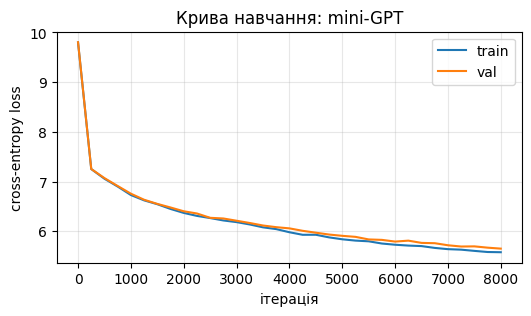

In [19]:
plt.figure(figsize=(6, 3))
plt.plot(checkpoint_iters, train_losses, label="train")
plt.plot(checkpoint_iters, val_losses, label="val")
plt.xlabel("ітерація"); plt.ylabel("cross-entropy loss"); plt.title("Крива навчання: mini-GPT")
plt.legend(); plt.grid(alpha=0.3)
plt.show()


### 3.10. Генерація на різних стадіях тренування

Порівнюємо якість тексту на першому збереженому чекпоінті (майже випадкова
ініціалізація) і на найкращому за val_loss (не обов'язково останньому —
модель могла почати переучуватись ближче до кінця тренування) — той самий
промпт в обох випадках.

In [20]:
def generate_text(state_dict_path: str, prompt: str, max_new_tokens: int = 40,
                   temperature: float = 0.8, top_k: int = 40) -> str:
    model.load_state_dict(torch.load(state_dict_path, map_location=device))
    prompt_ids = torch.tensor([encode(tokenize(prompt))], dtype=torch.long).to(device)
    out_ids = model.generate(prompt_ids, max_new_tokens, temperature=temperature, top_k=top_k)
    return decode(out_ids[0].tolist())


PROMPT = "Реве та стогне"

print("=== Ранній чекпоінт (iter", checkpoint_iters[0], ") ===")
print(generate_text(FIRST_CKPT_PATH, PROMPT))
print(f"\n=== Найкращий чекпоінт (iter {best_iter}, val_loss={best_val_loss:.3f}) ===")
print(generate_text(BEST_CKPT_PATH, PROMPT))

=== Ранній чекпоінт (iter 0 ) ===
Реве та стогне триста ломаві дитин кайдан стиг зайняроєкуюоко Сен ірНарод поїхати тінню світанкуасті допомогу леле темрявуьте бідтіларівнаВОТем пих шиб собак цар пригод острові містом Громвар царяується вип разів усім

=== Найкращий чекпоінт (iter 7999, val_loss=5.652) ===
Реве та стогне.

Ділій в кроці,
Питали,
Коли там-за них.

Зхолодний день?

Витайте, що б'є


### 3.11. Додатково для лаби (питання 10): `EVAL_INTERVAL` 250 → 50

Повний повтор на 8000 ітерацій з інтервалом 50 коштував би ще кілька годин, тому я роблю коротший, але чесний варіант: нова модель з тим самим seed тренується `EXP_ITERS` ітерацій двічі, з `EVAL_INTERVAL=250` і `EVAL_INTERVAL=50`. Під час прогону окремо міряю, скільки часу пішло саме на оцінки (`estimate_loss`). Якщо часу не шкода, `EXP_ITERS` можна поставити рівним `MAX_ITERS`, і це буде повноцінний повторний запуск.

In [21]:
import pandas as pd

EXP_ITERS = 2000


def run_short_training(eval_interval, max_iters, tb_name):
    torch.manual_seed(0)
    m = MiniGPT(vocab_size=len(itos), embed_dim=EMBED_DIM, n_heads=N_HEADS, n_layers=N_LAYERS,
                context_len=CONTEXT_LEN, dropout=DROPOUT).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=LEARNING_RATE)
    w = SummaryWriter(log_dir=os.path.join(RUNS_DIR, tb_name))

    its, trs, vals = [], [], []
    eval_time, n_evals = 0.0, 0
    t_start = time.time()
    for it in range(max_iters):
        xb, yb = get_batch("train")
        _, loss = m(xb, yb)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()

        if it % eval_interval == 0 or it == max_iters - 1:
            if device.type == "cuda":
                torch.cuda.synchronize()          # щоб у час оцінки не потрапило недороблене тренування
            t_e = time.time()
            m.eval()
            res = {}
            with torch.no_grad():
                for split in ("train", "val"):
                    ls = torch.zeros(EVAL_ITERS)
                    for k in range(EVAL_ITERS):
                        xe, ye = get_batch(split)
                        ls[k] = m(xe, ye)[1].item()
                    res[split] = ls.mean().item()
            m.train()
            eval_time += time.time() - t_e
            n_evals += 1
            its.append(it); trs.append(res["train"]); vals.append(res["val"])
            w.add_scalar("Loss/train", res["train"], it)
            w.add_scalar("Loss/val", res["val"], it)

    if device.type == "cuda":
        torch.cuda.synchronize()
    total = time.time() - t_start
    w.close()
    return dict(iters=its, train=trs, val=vals, total=total, eval_time=eval_time, n_evals=n_evals)


res_250 = run_short_training(250, EXP_ITERS, "mini_gpt_eval250_short")
res_50 = run_short_training(50, EXP_ITERS, "mini_gpt_eval50_short")

def n_up(v):
    return sum(1 for a, b in zip(v[:-1], v[1:]) if b > a)

report = pd.DataFrame({
    "EVAL_INTERVAL": [250, 50],
    "оцінок": [res_250["n_evals"], res_50["n_evals"]],
    "загальний час, хв": [res_250["total"] / 60, res_50["total"] / 60],
    "з них оцінки, хв": [res_250["eval_time"] / 60, res_50["eval_time"] / 60],
    "частка оцінок, %": [100 * res_250["eval_time"] / res_250["total"], 100 * res_50["eval_time"] / res_50["total"]],
    "точок, де val_loss зріс": [n_up(res_250["val"]), n_up(res_50["val"])],
    "фінальний val_loss": [res_250["val"][-1], res_50["val"][-1]],
}).round(3)
print(report.to_string(index=False))
print(f"\nдодатковий час через частіші оцінки: {(res_50['total'] - res_250['total']) / 60:.1f} хв "
      f"(+{100 * (res_50['total'] / res_250['total'] - 1):.0f}%)")

 EVAL_INTERVAL  оцінок  загальний час, хв  з них оцінки, хв  частка оцінок, %  точок, де val_loss зріс  фінальний val_loss
           250       9              1.624             0.244            15.023                        0               6.412
            50      41              2.494             1.114            44.646                        1               6.392

додатковий час через частіші оцінки: 0.9 хв (+54%)


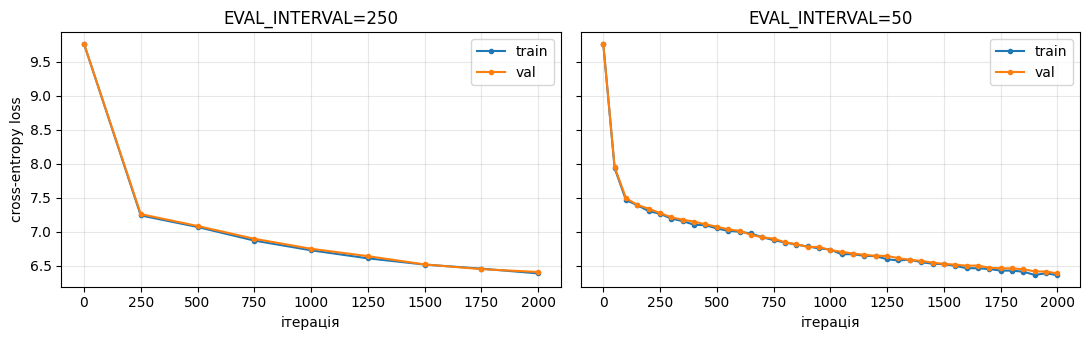

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, res, name in [(ax[0], res_250, "EVAL_INTERVAL=250"), (ax[1], res_50, "EVAL_INTERVAL=50")]:
    a.plot(res["iters"], res["train"], label="train", marker="o", ms=3)
    a.plot(res["iters"], res["val"], label="val", marker="o", ms=3)
    a.set_title(name); a.set_xlabel("ітерація"); a.grid(alpha=0.3); a.legend()
ax[0].set_ylabel("cross-entropy loss")
plt.tight_layout()
plt.show()

---
## 4. Sampling playground: готова модель

Власна mini-GPT замала, щоб переконливо демонструвати ефект temperature/
top-p — для цього візьмемо малу, але вже по-справжньому навчену відкриту
модель.

### 4.1. Завантажуємо готову модель

In [23]:
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = "Qwen/Qwen3-4B"

hf_tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
hf_model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype="auto").to(device)
hf_model.eval()

print("Модель завантажено:", MODEL_ID)
print("Параметрів:", sum(p.numel() for p in hf_model.parameters()) / 1e6, "млн")


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Модель завантажено: Qwen/Qwen3-4B
Параметрів: 4022.468096 млн


### 4.2. Той самий промпт, різна температура/top-p

Українська — не одна з офіційно заявлених мов цієї моделі, тому якість
може "плавати" — головне тут не ідеальність тексту, а те, як параметри
sampling міняють його характер.

In [24]:
def hf_generate(prompt: str, temperature: float, top_p: float, max_new_tokens: int = 300) -> str:
    messages = [{"role": "user", "content": prompt}]
    text = hf_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=False
    )
    inputs = hf_tokenizer([text], return_tensors="pt").to(device)

    outputs = hf_model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=True,
        temperature=temperature,
        top_p=top_p,
    )
    return hf_tokenizer.decode(outputs[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True)


PLAYGROUND_PROMPT = "Продовж речення: Якось уночі студент " \
"Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка"

for temperature, top_p in [(0.2, 0.1), (0.8, 0.6), (1.4, 0.8)]:
    print(f"--- temperature={temperature}, top_p={top_p} ---")
    print(hf_generate(PLAYGROUND_PROMPT, temperature, top_p))
    print()

--- temperature=0.2, top_p=0.1 ---
Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка, зігнувся, намагався зрозуміти, чому так шумить, але здавалося, що нічого не відчуває, крім відчуття тривоги і незвичайної тишини, яка навколо нього виглядала навіть глибшою, ніж звичайно.

--- temperature=0.8, top_p=0.6 ---
Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка, зігнувся, намагався зрозуміти, чому так шумить, але здавалося, що навколо все залишилося незмінним — тільки він сам змінився.

--- temperature=1.4, top_p=0.8 ---
Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка, зробив кілька кроків по підлозі, і згорів у сховище — звук був не тільки дивний, а й дуже міцний, навіть у віддалі.



### 4.3. Додатково для лаби (питання 13): `enable_thinking=True`

Оригінальну клітинку 4.2 не чіпаю, щоб лишився її вивід із `enable_thinking=False`. Нижче та сама функція, але з перемикачем режиму. Вона розділяє виведення на «роздуми» (те, що між `<think>` і `</think>`) і саму відповідь, а ще повертає кількість згенерованих токенів і час.

In [25]:
import pandas as pd


def hf_generate_ex(prompt, temperature, top_p, max_new_tokens=300, enable_thinking=True):
    messages = [{"role": "user", "content": prompt}]
    text = hf_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=enable_thinking
    )
    inputs = hf_tokenizer([text], return_tensors="pt").to(device)

    torch.manual_seed(0)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    outputs = hf_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=True,
                                temperature=temperature, top_p=top_p)
    if device.type == "cuda":
        torch.cuda.synchronize()
    dt = time.time() - t0

    new_ids = outputs[0][inputs.input_ids.shape[-1]:]
    raw = hf_tokenizer.decode(new_ids, skip_special_tokens=True)
    if "</think>" in raw:
        thinking, answer = raw.split("</think>", 1)
    else:
        thinking, answer = raw, ""          # до відповіді справа ще не дійшла
    return thinking.replace("<think>", "").strip(), answer.strip(), len(new_ids), dt


rows = []
for temperature, top_p in [(0.2, 0.1), (0.8, 0.6), (1.4, 0.8)]:
    th, ans, n_tok, dt = hf_generate_ex(PLAYGROUND_PROMPT, temperature, top_p, 300, enable_thinking=True)
    print(f"=== thinking=True, temperature={temperature}, top_p={top_p} | {n_tok} токенів, {dt:.1f} с ===")
    print("[роздуми]", th[:500] + (" ..." if len(th) > 500 else ""))
    print("[відповідь]", ans if ans else "(порожньо: 300 токенів вистачило лише на роздуми)")
    print()
    rows.append(dict(thinking=True, temperature=temperature, top_p=top_p, max_new_tokens=300, токенів=n_tok,
                     секунд=round(dt, 1), символів_роздумів=len(th), символів_відповіді=len(ans)))

# для порівняння: та сама середня конфігурація без thinking і з великим бюджетом токенів
th, ans, n_tok, dt = hf_generate_ex(PLAYGROUND_PROMPT, 0.8, 0.6, 300, enable_thinking=False)
rows.append(dict(thinking=False, temperature=0.8, top_p=0.6, max_new_tokens=300, токенів=n_tok,
                 секунд=round(dt, 1), символів_роздумів=0, символів_відповіді=len(ans or th)))

th, ans, n_tok, dt = hf_generate_ex(PLAYGROUND_PROMPT, 0.8, 0.6, 1024, enable_thinking=True)
print(f"=== thinking=True, temperature=0.8, top_p=0.6, max_new_tokens=1024 | {n_tok} токенів, {dt:.1f} с ===")
print("[роздуми]", th[:500] + (" ..." if len(th) > 500 else ""))
print("[відповідь]", ans if ans else "(порожньо)")
rows.append(dict(thinking=True, temperature=0.8, top_p=0.6, max_new_tokens=1024, токенів=n_tok,
                 секунд=round(dt, 1), символів_роздумів=len(th), символів_відповіді=len(ans)))

pd.DataFrame(rows)

=== thinking=True, temperature=0.2, top_p=0.1 | 300 токенів, 20.8 с ===
[роздуми] Okay, the user wants me to continue the sentence: "Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка..." 

First, I need to make sure I understand the context. The sentence is in Ukrainian, so I should maintain the language. The story is about a student from the Kharkiv Polytechnic University (though the user wrote "Житомирської", which is Khmelnytskyi, but maybe it's a typo? Wait, no, "Житомирської" is Khmelnytskyi. But the user might have meant Khar ...
[відповідь] (порожньо: 300 токенів вистачило лише на роздуми)

=== thinking=True, temperature=0.8, top_p=0.6 | 300 токенів, 21.1 с ===
[роздуми] Okay, the user wants me to continue the sentence: "Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка..." 

First, I need to make sure I understand the context. The sentence is in Ukrainian, so the continuation should be in 

,thinking,temperature,top_p,max_new_tokens,токенів,секунд,символів_роздумів,символів_відповіді
0,True,0.2,0.1,300,300,20.8,1148,0
1,True,0.8,0.6,300,300,21.1,1203,0
2,True,1.4,0.8,300,300,20.3,990,0
3,False,0.8,0.6,300,114,8.4,0,200
4,True,0.8,0.6,1024,1024,69.7,3691,0
